# SignalProcessing-02 — La convolution et le filtrage

**Navigation** : [<< SignalProcessing-01 — Le signal dans le domaine fréquentiel](SignalProcessing-01-Le-Signal-Dans-Le-Domaine-Frequentiel.ipynb) | [SignalProcessing-04 — Le signal dans le canal : la capacité →](SignalProcessing-04-Le-Signal-Dans-Le-Canal-Python.ipynb) | [Index de la série](../README.md)

**Sous-série du hub « Information & calcul » (#27092)** — le signal du carnet 01
traverse maintenant un **système**. L'opérateur central est la **convolution** :
la sortie d'un système linéaire est l'entrée *convoluée* avec sa **réponse
impulsionnelle**. Dans le domaine fréquentiel, filtrer revient à **multiplier**
par la **réponse en fréquence**.

*Bibliothèque : numpy (`np.convolve`, `np.fft`).* · *Source : Oppenheim & Schafer,
Discrete-Time Signal Processing (ch. filtrage).* · **Prev :** 01 — Le signal dans le domaine fréquentiel (carnet en PR, #27087)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams['figure.figsize'] = (9, 3)
np.random.seed(0)
print('numpy', np.__version__)

numpy 2.5.2


## Un signal à filtrer

On construit un signal composé de trois parties : une composante **basse
fréquence** (le signal utile), une composante **haute fréquence** (à retirer)
et du **bruit** aléatoire. Le but du carnet : récupérer la composante utile.

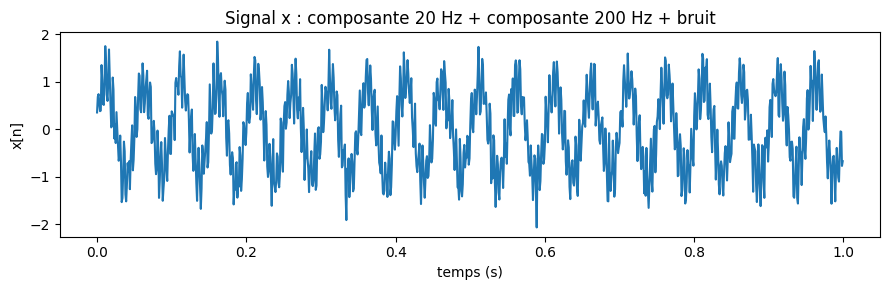

In [2]:
fs = 1000.0                      # fréquence d'échantillonnage (Hz)
N  = 1000                        # nombre d'échantillons
t  = np.arange(N) / fs

f_low  = 20.0                   # composante utile (basse fréquence)
f_high = 200.0                  # composante à retirer (haute fréquence)

x = (np.sin(2*np.pi*f_low*t)
     + 0.5*np.sin(2*np.pi*f_high*t)
     + 0.2*np.random.randn(N))

plt.figure(figsize=(9,3))
plt.plot(t, x)
plt.xlabel('temps (s)'); plt.ylabel('x[n]')
plt.title('Signal x : composante 20 Hz + composante 200 Hz + bruit')
plt.tight_layout(); plt.show()

## §1 — La convolution, opérateur central

La **convolution discrète** de l'entrée $x$ par la réponse impulsionnelle $h$ :

$$y[n] = (x * h)[n] = \sum_{k} x[k]\; h[n-k]$$

Elle « étale » chaque échantillon d'entrée, pondéré par $h$, puis somme. Une
**moyenne glissante** (des $h$ tous égaux) lisse le signal : c'est déjà un
**filtre passe-bas** — la composante haute fréquence en sort atténuée.

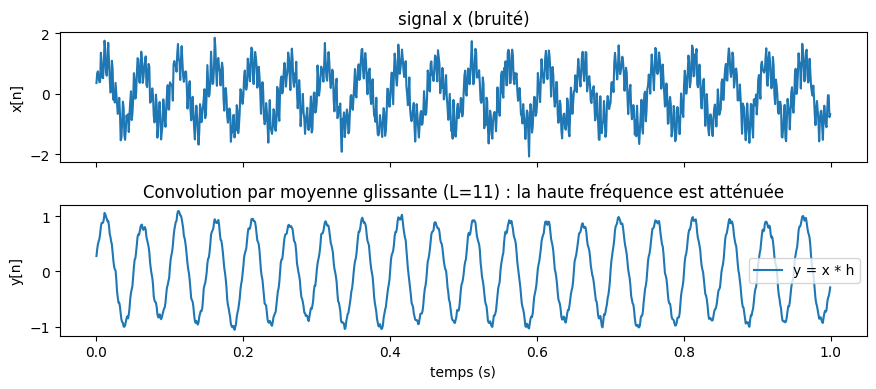

In [3]:
L = 11
h = np.ones(L) / L              # réponse impulsionnelle : moyenne glissante de L points
y = np.convolve(x, h, mode='same')

fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
ax[0].plot(t, x); ax[0].set_ylabel('x[n]'); ax[0].set_title('signal x (bruité)')
ax[1].plot(t, y, label='y = x * h'); ax[1].legend(); ax[1].set_ylabel('y[n]'); ax[1].set_xlabel('temps (s)')
ax[1].set_title(f'Convolution par moyenne glissante (L={L}) : la haute fréquence est atténuée')
plt.tight_layout(); plt.show()

### Lecture du résultat

La sortie $y$ ne montre plus la composante 200 Hz : la moyenne glissante l'a
absorbée. **Convoluer, c'est filtrer** — la forme de $h$ décide ce qui passe.
On va maintenant *mesurer* ce que $h$ laisse passer : sa réponse en fréquence.

## §2 — Le théorème de la convolution

La **réponse en fréquence** $H(f)$ est la transformée de Fourier de $h$. Le
**théorème de la convolution** dit que convoluer dans le domaine temporel
équivaut à **multiplier** dans le domaine fréquentiel :

$$\mathcal{F}\{x * h\} = \mathcal{F}\{x\}\;\cdot\;\mathcal{F}\{h\}$$

On le vérifie numériquement sur la convolution linéaire complète.

Écart max |FFT(x*h) - X·H| = 1.271e-13   (≈ 0 : théorème de la convolution)


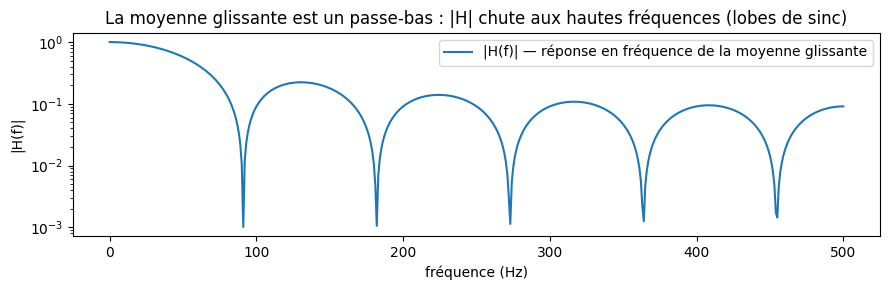

In [4]:
# Convolution LINEAIRE complète (longueur N+L-1), FFT zéro-bordurée (n=2N, pas d'enrouillage)
nfft = 2*N
y_full = np.convolve(x, h)                       # longueur N+L-1
Y_conv = np.fft.fft(y_full, n=nfft)
X  = np.fft.fft(x, n=nfft)
H  = np.fft.fft(h, n=nfft)
err = np.max(np.abs(Y_conv - X*H))
print(f'Écart max |FFT(x*h) - X·H| = {err:.3e}   (≈ 0 : théorème de la convolution)')

freqs = np.fft.rfftfreq(N, d=1/fs)
Hr    = np.fft.rfft(h, n=N)
plt.figure(figsize=(9,3))
plt.semilogy(freqs, np.abs(Hr)+1e-12, label='|H(f)| — réponse en fréquence de la moyenne glissante')
plt.xlabel('fréquence (Hz)'); plt.ylabel('|H(f)|'); plt.legend()
plt.title('La moyenne glissante est un passe-bas : |H| chute aux hautes fréquences (lobes de sinc)')
plt.tight_layout(); plt.show()

### Lecture du résultat

$|H(f)|$ a la forme d'un **sinc** : proche de 1 vers le bas, nul (puis de petits
lobes) vers le haut. La moyenne glissante **coupe** donc les hautes fréquences —
c'est un filtre **passe-bas**. Son premier zéro (première coupure) est autour de
$f = f_s / L$.

## §3 — Les filtres : FIR (RI) et IIR (RR)

Deux grandes familles de filtres numériques :

- **FIR** (Réponse Impulsionnelle **finie**) : $h$ de longueur bornée, pas de
  récurrence. Stable par construction, phase linéaire possible.
- **IIR** (à **Récurrence**) : la sortie dépend des sorties passées
  ($y[n] = \sum b_i x[n-i] - \sum a_i y[n-i]$). Réponse impulsionnelle
  **infinie** — coupure plus raide pour peu de coefficients.

In [5]:
# --- FIR : passe-bas par moyenne glissante, coupure mesurée ---
f_r = np.fft.rfftfreq(N, d=1/fs)
mag = np.abs(np.fft.rfft(h, n=N))
# première fréquence où |H| passe sous 0.5 (≈ première coupure du sinc)
idx = np.argmax(mag < 0.5)
f_coup_FIR = f_r[idx]
print(f'FIR passe-bas (moyenne glissante L={L}) : première coupure |H|=0.5 à ≈ {f_coup_FIR:.0f} Hz')
print(f'  (borne théorique fs/L = {fs/L:.0f} Hz)')

# --- IIR : passe-bas du 1er ordre par récurrence ---
a = 0.2
y_iir = np.zeros(N)
for n in range(1, N):
    y_iir[n] = a*x[n] + (1-a)*y_iir[n-1]
# réponse impulsionnelle théorique a·(1-a)^k, coupure -3 dB mesurée
imp = np.array([a*(1-a)**k for k in range(256)])
Hm  = np.abs(np.fft.rfft(imp, n=4096))
fm  = np.fft.rfftfreq(4096, d=1/fs)
f_coup_IIR = fm[np.argmax(Hm < 1/np.sqrt(2))]
print(f'IIR passe-bas 1er ordre (a={a}) : coupure -3 dB à ≈ {f_coup_IIR:.0f} Hz')

FIR passe-bas (moyenne glissante L=11) : première coupure |H|=0.5 à ≈ 56 Hz
  (borne théorique fs/L = 91 Hz)
IIR passe-bas 1er ordre (a=0.2) : coupure -3 dB à ≈ 36 Hz


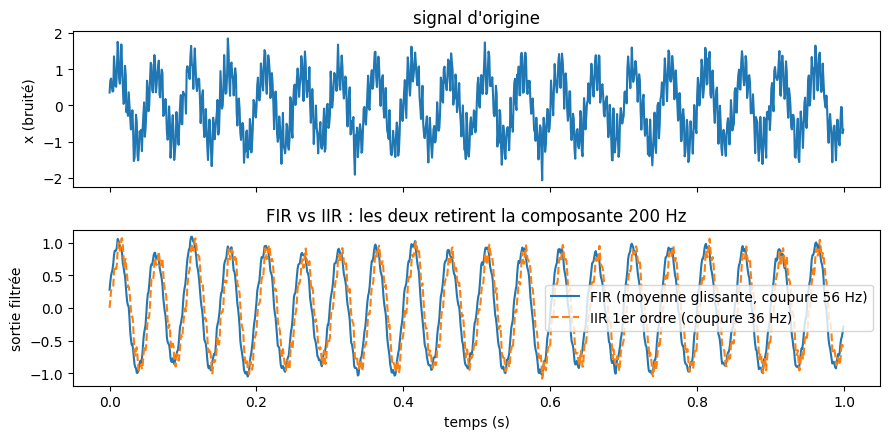

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
ax[0].plot(t, x);  ax[0].set_ylabel('x (bruité)');  ax[0].set_title('signal d\'origine')
ax[1].plot(t, y, label=f'FIR (moyenne glissante, coupure {f_coup_FIR:.0f} Hz)')
ax[1].plot(t, y_iir, '--', label=f'IIR 1er ordre (coupure {f_coup_IIR:.0f} Hz)')
ax[1].legend(); ax[1].set_ylabel('sortie filtrée'); ax[1].set_xlabel('temps (s)')
ax[1].set_title('FIR vs IIR : les deux retirent la composante 200 Hz')
plt.tight_layout(); plt.show()

### Lecture du résultat

Les deux filtres récupèrent la composante 20 Hz et suppriment la composante
200 Hz. Le **FIR** (moyenne glissante) a une coupure douce ; l'**IIR** atteint
une coupure plus raide avec un seul coefficient de récurrence — au prix d'une
réponse impulsionnelle infinie et d'une stabilité à surveiller (les pôles de $H$).

## §4 — Filtrer dans le domaine fréquentiel

La méthode pratique : on passe le signal en fréquence, on **multiplie** par la
réponse en fréquence du filtre, on revient en temps. C'est exactement le
théorème de la convolution mis à profit — et c'est ce que font les FFT en
production. La **bande passante** $B$ que le filtre laisse ouverte est celle qui
alimentera, au carnet 04, la formule de Shannon-Hartley
$C = B\log_2(1+S/N)$. **Renvoi →** InformationTheory — la capacité (série en construction, #27077).

In [7]:
# Filtrage en fréquence = convolution LINEAIRE par FFT, zéro-bordurée (nfft=2N, pas d'enrouillage)
nfft = 2*N
X  = np.fft.fft(x, n=nfft)
H  = np.fft.fft(h, n=nfft)
y_freq = np.fft.ifft(X*H)[L//2 : L//2 + N].real   # alignement 'same'
print(f'Max |y_temporel - y_frequence| = {np.max(np.abs(y - y_freq)):.3e}   (identiques)')
print('Filtrer en fréquence == convoluer en temps : même sortie.')

Max |y_temporel - y_frequence| = 5.551e-16   (identiques)
Filtrer en fréquence == convoluer en temps : même sortie.


## Exercices

In [8]:
# Exercice 1 — Réponse en fréquence d'une moyenne glissante
# Calculez |H(f)| d'une moyenne glissante de L=5 points à la fréquence de Nyquist
# (f = fs/2). Valeur attendue : ≈ 1/L = 0,2 — ce n'est PAS nul. Pourquoi un
# moyenneur de longueur impaire ne s'annule-t-il pas à Nyquist ? (Zéros du
# moyenneur L=5 : multiples de fs/5 = 200 Hz, jamais à fs/2 = 500 Hz.)
H_nyquist = None  # TODO etudiant : |H(fs/2)| pour L=5

In [9]:
# Exercice 2 — Le FIR retire-t-il ENTIEREMENT la haute fréquence ?
# Projetez la composante 200 Hz de y (moyenne glissante L=11) par multiplication
# avec sin/cos puis moyenne. L'amplitude résiduelle est-elle nulle ?
residuel_200hz = None  # TODO etudiant

In [10]:
# Exercice 3 — Choisir a pour une fréquence de coupe cible
# Pour le filtre IIR y[n]=a·x[n]+(1-a)·y[n-1], trouvez numériquement la valeur
# de a qui donne une coupure -3 dB à f_c = 50 Hz.
a_cible = None  # TODO etudiant

In [11]:
# Exercice 4 — Construire un passe-haut à partir du passe-bas
# Inversion spectrale : H_hp(f) = 1 - H_lp(f) (normalisé pour que le passe-bas
# vaille 1 en basse fréquence). Construisez H_hp et appliquez-le à x.
y_passe_haut = None  # TODO etudiant

## Pour aller plus loin

- **03 — La quantification** (carnet en PR, #27391) :
  le passage au discret, le bruit de quantification et son rapport signal/bruit.
  *Renvoi →* **Compression** (coder la source).
- **04 — Le signal dans le canal : la capacité**, [carnet 04](SignalProcessing-04-Le-Signal-Dans-Le-Canal-Python.ipynb) :
  le canal vu comme une bande passante plus un bruit ajouté, le rapport
  signal/bruit mesuré en décibels, et la formule de Shannon-Hartley vérifiée sur
  un canal simulé.
- **InformationTheory (#27077)** : la capacité du canal que la bande passante
  $B$ du filtre alimente — le pont $C = B\log_2(1+S/N)$ au carnet 04.
- **Cryptography (#27081)** : le même canal, mais **adversarial** — protéger le
  message au lieu de le corriger.
